# FoodieMine: Restaurant Success Analysis using Data Mining
BCSE208L Data Mining · Zomato Bangalore dataset

This notebook walks through every step of the project. The logic lives in the `foodiemine` package; each cell calls one piece and shows its output.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 20); pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 80)
from foodiemine import config, preprocess, warehouse, patterns, classify, cluster, figures
config.ensure_dirs()

## Step 1: Data preprocessing (Module 3)
Clean `rate` ("4.1/5", "NEW", "-") and `approx_cost` ("1,200"), merge duplicate listings of the same restaurant, handle missing values, discretise cost/rating, and create the *Highly Rated* label (rating ≥ 4.0).

In [2]:
raw = preprocess.load_raw()
print(raw.shape)
raw[['name','rate','approx_cost(for two people)','listed_in(type)']].head()

(51717, 11)


,name,rate,approx_cost(for two people),listed_in(type)
0,Jalsa,4.1/5,800,Buffet
1,Spice Elephant,4.1/5,800,Buffet
2,San Churro Cafe,3.8/5,800,Buffet
3,Addhuri Udupi Bhojana,3.7/5,300,Buffet
4,Grand Village,3.8/5,600,Buffet


In [3]:
raw['rate'].value_counts().head(10)

rate
NEW       2208
3.9/5     2098
3.8/5     2022
3.7/5     2011
3.9 /5    1874
3.8 /5    1851
3.7 /5    1810
3.6/5     1773
4.0/5     1609
4.0 /5    1574
Name: count, dtype: int64

In [4]:
df, unrated, report = preprocess.preprocess(raw)
preprocess.save(df, unrated, report)
report

{'raw_rows': 51717,
 'raw_columns_kept': ['name',
  'address',
  'online_order',
  'book_table',
  'rate',
  'votes',
  'location',
  'rest_type',
  'cuisines',
  'approx_cost(for two people)',
  'listed_in(type)'],
 'exact_duplicate_rows': 16664,
 'unique_restaurants': 12499,
 'listings_merged_away': 22554,
 'missing_before': {'rate': 2992,
  'location': 9,
  'rest_type': 62,
  'cuisines': 18,
  'approx_cost': 55},
 'unrated_new_restaurants': 2978,
 'popularity_vote_cutoffs': [24.0, 120.0],
 'final_rated_restaurants': 9503,
 'highly_rated_share': 0.221,
 'cost_level_counts': {'Low': 5019, 'Medium': 3291, 'High': 1193},
 'rating_level_counts': {'Average': 4145, 'Poor': 3258, 'Good': 2100}}

In [5]:
df[['name','location','area','zone','primary_type','service_type','cuisines','rate','rating_level',
    'approx_cost','cost_level','votes','popularity','highly_rated']].head()

,name,location,area,zone,primary_type,service_type,cuisines,rate,rating_level,approx_cost,cost_level,votes,popularity,highly_rated
0,Jalsa,Banashankari,Banashankari,South,Casual Dining,Buffet,"North Indian, Mughlai, Chinese",4.1,Good,800.0,Medium,804,Popular,1
1,Spice Elephant,Banashankari,Banashankari,South,Casual Dining,Buffet,"Chinese, North Indian, Thai",4.1,Good,800.0,Medium,787,Popular,1
2,San Churro Cafe,Banashankari,Banashankari,South,Cafe,Buffet,"Cafe, Mexican, Italian",3.8,Average,800.0,Medium,924,Popular,0
3,Addhuri Udupi Bhojana,Banashankari,Banashankari,South,Quick Bites,Buffet,"South Indian, North Indian",3.7,Average,300.0,Low,88,Known,0
4,Grand Village,Basavanagudi,Basavanagudi,South,Casual Dining,Buffet,"North Indian, Rajasthani",3.8,Average,600.0,Medium,166,Popular,0


## Step 2: Data warehouse and OLAP (Module 1)
Star schema in SQLite: `fact_restaurant` + `dim_location`, `dim_cuisine`, `dim_type`, `dim_service` (+ a bridge table for the many-to-many restaurant↔cuisine link).

In [6]:
warehouse.build(df)

{'dim_location': 92,
 'dim_cuisine': 106,
 'dim_type': 89,
 'dim_service': 4,
 'fact_restaurant': 9503,
 'bridge_restaurant_cuisine': 22981}

In [7]:
warehouse.query('SELECT * FROM dim_location LIMIT 5')

,location_id,location,area,zone,city
0,1,BTM,BTM,South,Bangalore
1,2,Banashankari,Banashankari,South,Bangalore
2,3,Banaswadi,Banaswadi,East,Bangalore
3,4,Bannerghatta Road,Bannerghatta Road,South,Bangalore
4,5,Basavanagudi,Basavanagudi,South,Bangalore


**Roll-up**: location → area → zone → city

In [8]:
warehouse.rollup('zone')

,zone,restaurants,avg_rating,avg_votes,avg_cost,pct_highly_rated
0,South,3981,3.63,234.0,474.0,21.0
1,East,2914,3.59,263.0,557.0,19.9
2,North,1283,3.64,192.0,494.0,23.4
3,Central,1001,3.73,312.0,803.0,33.8
4,West,324,3.59,130.0,432.0,13.3


**Drill-down**: South zone → locations

In [9]:
warehouse.drill_down('South').head(10)

,area,location,restaurants,avg_rating,avg_votes,avg_cost,pct_highly_rated
0,BTM,BTM,538,3.56,133.0,403.0,12.8
1,HSR,HSR,529,3.64,219.0,469.0,21.0
2,Electronic City,Electronic City,458,3.47,121.0,523.0,10.3
3,JP Nagar,JP Nagar,388,3.64,231.0,489.0,22.2
4,Bannerghatta Road,Bannerghatta Road,355,3.48,147.0,458.0,11.0
5,Jayanagar,Jayanagar,313,3.76,281.0,473.0,31.3
6,Koramangala,Koramangala 5th Block,245,3.92,736.0,597.0,51.0
7,Banashankari,Banashankari,228,3.62,172.0,410.0,17.5
8,Basavanagudi,Basavanagudi,180,3.67,186.0,353.0,21.1
9,Koramangala,Koramangala 6th Block,134,3.73,338.0,571.0,34.3


**Slice**: only cafés

In [10]:
warehouse.slice_('Cafe')

,zone,restaurants,avg_rating,avg_votes,avg_cost,pct_highly_rated
0,South,264,3.80,424.0,621.0,42.0
1,Central,86,3.79,376.0,700.0,43.0
2,North,85,3.77,257.0,624.0,37.6
3,East,136,3.73,235.0,595.0,37.5
4,West,7,3.41,46.0,671.0,0.0


**Dice**: cafés in Koramangala with Low cost

In [11]:
warehouse.dice('Cafe', 'Koramangala', 'Low')

,name,location,rate,votes,approx_cost,online_order,book_table
0,Fabindia Cafe,Koramangala 2nd Block,4.2,226,200.0,No,No
1,Kalmane Koffees,Koramangala 7th Block,4.1,367,350.0,No,No
2,Blue Tokai Coffee Roasters,Koramangala 8th Block,4.0,79,400.0,Yes,No
3,Barista,Koramangala 4th Block,3.6,36,300.0,No,No
4,Om's Cafe Prana,Koramangala 7th Block,3.6,17,300.0,No,No
5,Barista,Koramangala 5th Block,3.5,66,300.0,No,No
6,Smack Cafe,Koramangala 1st Block,3.3,4,400.0,Yes,No
7,G Resto Cafe,Koramangala 4th Block,3.3,4,400.0,No,No


**Pivot**: average rating by zone × cost level

In [12]:
warehouse.pivot('zone', 'cost_level')

cost_level,Low,Medium,High
zone,,,
Central,3.55,3.70,4.00
East,3.50,3.54,4.02
North,3.58,3.63,4.00
South,3.57,3.63,3.93
West,3.53,3.66,3.75


In [13]:
warehouse.services_effect()

,online_order,book_table,restaurants,avg_rating,avg_votes,avg_cost,pct_highly_rated
0,No,No,3167,3.51,129.0,468.0,13.4
1,No,Yes,449,4.15,1009.0,1608.0,75.1
2,Yes,No,5388,3.61,172.0,440.0,18.3
3,Yes,Yes,499,4.08,1017.0,1032.0,70.9


**Market gaps**: high demand, low supply

In [14]:
olap = warehouse.run_olap_demo()
olap['market_gaps'].head(10)

,area,cuisine_group,restaurants,area_restaurants,avg_rating,avg_votes,demand_index,supply_index,gap_score
0,JP Nagar,Middle Eastern,3,388,3.61,396.75,1.36,0.30,4.48
1,Bannerghatta Road,Middle Eastern,8,355,3.68,662.33,3.57,0.89,4.02
2,BTM,Continental & Western,36,538,3.88,664.85,1.42,0.45,3.19
3,Bellandur,Seafood,4,274,3.44,301.75,1.36,0.43,3.19
4,Sahakara Nagar,North Indian,11,40,3.60,409.27,1.94,0.64,3.02
5,Kumaraswamy Layout,Desserts & Bakery,6,65,3.46,103.29,1.68,0.58,2.90
6,Frazer Town,Beverages & Cafe,16,146,3.71,308.39,1.84,0.66,2.79
7,Electronic City,Seafood,14,458,3.50,453.50,2.44,0.89,2.74
8,Malleshwaram,Asian,45,204,3.77,672.05,1.75,0.67,2.62
9,Seshadripuram,Fast Food & Snacks,11,46,3.76,275.07,1.98,0.78,2.53


## Step 3: Frequent pattern mining (Module 4)
Each restaurant is a transaction, e.g. `{Cuisine=North Indian, Cost=Medium, OnlineOrder=Yes, Rating=Good}`.

In [15]:
tx = patterns.build_transactions(df)
tx[0]

['Cost=Medium',
 'Cuisine=Chinese',
 'Cuisine=Mughlai',
 'Cuisine=North Indian',
 'OnlineOrder=Yes',
 'Popularity=Popular',
 'Rating=Good',
 'Service=Buffet',
 'TableBooking=Yes',
 'Type=Casual Dining',
 'Zone=South']

Apriori (mlxtend), FP-Growth (mlxtend) and Eclat (own implementation on the vertical tidset format).

In [16]:
pats = patterns.run(df)
pats['pattern_algorithm_comparison']

,min_support,algorithm,seconds,itemsets,all_three_agree
0,0.20,Apriori,0.0062,86,True
1,0.20,FP-Growth,0.0499,86,True
2,0.20,Eclat,0.0191,86,True
3,0.10,Apriori,0.0186,418,True
4,0.10,FP-Growth,0.0752,418,True
5,0.10,Eclat,0.0193,418,True
6,0.05,Apriori,0.0492,1320,True
7,0.05,FP-Growth,0.1772,1320,True
8,0.05,Eclat,0.0211,1320,True
9,0.03,Apriori,0.1186,2584,True


In [17]:
pats['frequent_itemsets'].head(15)

,itemset,length,support
0,TableBooking=No,1,0.900242
1,OnlineOrder=Yes,1,0.619489
2,"OnlineOrder=Yes, TableBooking=No",2,0.566979
3,Service=Dine-out,1,0.531095
4,Cost=Low,1,0.528149
5,"Cost=Low, TableBooking=No",2,0.526781
6,"Service=Dine-out, TableBooking=No",2,0.493318
7,Rating=Average,1,0.436178
8,Zone=South,1,0.418920
9,Cuisine=North Indian,1,0.414290


Rules that lead to a **Good** rating (redundant supersets pruned):

In [18]:
pats['rules_good_rating'][['rule','support','confidence','lift']].head(15)

,rule,support,confidence,lift
0,"{Cuisine=Mediterranean, TableBooking=Yes} -> {Rating=Good}",0.006103,0.966667,4.374397
1,"{Cuisine=European, TableBooking=Yes} -> {Rating=Good}",0.006945,0.916667,4.148135
2,"{Cuisine=Cafe, Cuisine=Italian, TableBooking=Yes} -> {Rating=Good}",0.005051,0.905660,4.098329
3,"{Cost=High, Cuisine=BBQ, TableBooking=Yes} -> {Rating=Good}",0.005051,0.905660,4.098329
4,"{Cuisine=Italian, TableBooking=Yes, Zone=East} -> {Rating=Good}",0.005682,0.900000,4.072714
5,"{Cuisine=Italian, OnlineOrder=Yes, TableBooking=Yes} -> {Rating=Good}",0.010102,0.888889,4.022434
6,"{Cost=High, Cuisine=Salad, TableBooking=Yes} -> {Rating=Good}",0.005051,0.888889,4.022434
7,"{Cost=High, Cuisine=Asian, TableBooking=Yes} -> {Rating=Good}",0.009892,0.886792,4.012947
8,"{Service=Pubs and bars, TableBooking=Yes, Type=Casual Dining} -> {Rating=Good}",0.007050,0.881579,3.989355
9,"{Cuisine=Pizza, OnlineOrder=Yes, TableBooking=Yes} -> {Rating=Good}",0.005472,0.881356,3.988345


Rules that lead to a **Poor** rating:

In [19]:
pats['rules_poor_rating'][['rule','support','confidence','lift']].head(10)

,rule,support,confidence,lift
0,"{Cuisine=Chinese, OnlineOrder=No, Service=Delivery} -> {Rating=Poor}",0.005893,0.700000,2.041774
1,"{Cuisine=North Indian, OnlineOrder=No, Type=Delivery} -> {Rating=Poor}",0.005577,0.688312,2.007681
2,"{Cuisine=North Indian, OnlineOrder=No, Service=Delivery} -> {Rating=Poor}",0.010733,0.680000,1.983438
3,"{Cuisine=Biryani, OnlineOrder=No, Type=Quick Bites} -> {Rating=Poor}",0.014206,0.661765,1.930249
4,"{Cost=Medium, OnlineOrder=No, Service=Delivery} -> {Rating=Poor}",0.006840,0.637255,1.858758
5,"{Cost=Low, Cuisine=Biryani, OnlineOrder=No} -> {Rating=Poor}",0.014311,0.635514,1.853680
6,"{Cuisine=Biryani, OnlineOrder=No, Zone=East} -> {Rating=Poor}",0.008524,0.632812,1.845800
7,"{OnlineOrder=No, Service=Delivery, Type=Takeaway} -> {Rating=Poor}",0.005998,0.619565,1.807160
8,"{Cost=Low, Cuisine=Chinese, OnlineOrder=No} -> {Rating=Poor}",0.026413,0.612195,1.785663
9,"{OnlineOrder=No, Type=Takeaway} -> {Rating=Poor}",0.007682,0.608333,1.774399


## Step 4: Classification (Module 5)
Predict *Highly Rated* from pre-review features only. Naive Bayes, KNN (lazy learner), class balancing, bagging ensembles and a Bayesian Belief Network. Evaluated with a stratified 80/20 split plus 5-fold cross-validation. *(about 1 minute)*

In [20]:
clf = classify.run(df, unrated)
clf['metrics']

,model,cv_accuracy,cv_accuracy_std,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Majority baseline,0.7790,0.0001,0.0000,0.7791,0.0000,0.0000,0.0000,0.5000
1,Naive Bayes,0.7812,0.0044,0.5154,0.7885,0.5210,0.5310,0.5259,0.7815
2,Naive Bayes (balanced priors),0.7447,0.0074,0.5206,0.7638,0.4746,0.6452,0.5469,0.7815
3,KNN (k=9),0.8245,0.0061,0.5385,0.8159,0.6182,0.4357,0.5112,0.7537
4,KNN (k=9) + oversampling,0.7299,0.0064,0.5335,0.7359,0.4334,0.6357,0.5154,0.7376
5,Bagging (KNN),0.8256,0.0101,0.5327,0.8196,0.6314,0.4405,0.5189,0.7663
6,Bagging (decision trees),0.8346,0.0028,0.5495,0.8296,0.6739,0.4429,0.5345,0.7999
7,Bayesian Belief Network (expert),NaN,NaN,NaN,0.8206,NaN,NaN,0.4364,0.7340
8,Bayesian Belief Network (hill-climb),NaN,NaN,NaN,0.8206,NaN,NaN,0.4364,0.7337


In [21]:
print('Best model by CV F1:', clf['best_name'])
clf['knn_grid'].sort_values('cv_f1', ascending=False).head()

Best model by CV F1: Bagging (decision trees)


,k,weights,cv_f1
3,9,distance,0.538460
2,9,uniform,0.536433
5,15,distance,0.530311
0,5,uniform,0.522670
4,15,uniform,0.521813


Naive Bayes likelihood ratios: which feature values raise or lower the odds of a high rating.

In [22]:
clf['signals'].head(12)

,feature,likelihood_ratio,restaurants
0,primary_type = Microbrewery,54.199,31
1,primary_type = Fine Dining,11.989,91
2,Cuisine: Asian,8.775,190
3,location = Lavelle Road,7.440,52
4,primary_type = Pub,7.227,90
5,service_type = Pubs and bars,5.465,330
6,cost_level = High,5.246,1193
7,Cuisine: American,4.891,201
8,location = Church Street,4.375,55
9,Cuisine: Salad,4.194,182


Bayesian Belief Network: expert structure vs. structure learned by hill-climbing (BIC).

In [23]:
print('expert :', clf['bbn']['expert_edges'])
print('learned:', clf['bbn']['learned_edges'])
clf['bbn']['queries']

expert : [('Type', 'Cost'), ('Type', 'OnlineOrder'), ('Cost', 'TableBooking'), ('Cost', 'Rating'), ('TableBooking', 'Rating'), ('OnlineOrder', 'Rating'), ('Rating', 'Popularity')]
learned: [('Cost', 'Type'), ('OnlineOrder', 'Popularity'), ('OnlineOrder', 'Cost'), ('OnlineOrder', 'TableBooking'), ('TableBooking', 'Cost'), ('TableBooking', 'Type'), ('Rating', 'Popularity'), ('Rating', 'TableBooking'), ('Popularity', 'TableBooking'), ('Popularity', 'Cost')]


,Cost,TableBooking,OnlineOrder,P(Highly rated),training_restaurants
0,Low,No,No,0.103,1519
1,Low,No,Yes,0.137,2452
2,Low,Yes,No,0.853,2
3,Low,Yes,Yes,0.131,10
4,Medium,No,No,0.153,749
5,Medium,No,Yes,0.223,1727
6,Medium,Yes,No,0.593,42
7,Medium,Yes,Yes,0.591,147
8,High,No,No,0.292,247
9,High,No,Yes,0.405,146


In [24]:
clf['bbn']['diagnostic']

,Cost,P(Cost),P(Cost | Highly rated)
0,High,0.126,0.349
1,Low,0.524,0.295
2,Medium,0.351,0.356


Scoring the **new / unrated** restaurants:

In [25]:
clf['new_predictions'].head(10)

,name,location,primary_type,approx_cost,cuisines,online_order,book_table,p_highly_rated
0,Cafe Noir,Koramangala 7th Block,Casual Dining,1500.0,"European, French, Salad",1,0,0.975
1,Toscano Wine Connection,"Varthur Main Road, Whitefield",Casual Dining,1200.0,"Mediterranean, Italian",0,0,0.957
2,Blu Oyster,Indiranagar,Casual Dining,1500.0,"Seafood, Continental, European, Mediterranean",0,1,0.954
3,One Night In Bangkok,Indiranagar,Casual Dining,1400.0,"Asian, Thai",0,0,0.941
4,Inntense Restobar,Indiranagar,Bar,1600.0,"Finger Food, Continental, North Indian, Pizza, Burger",0,1,0.937
5,Watson's,Indiranagar,Pub,1300.0,"Finger Food, Salad, Chinese, Continental",1,0,0.896
6,Alechemy,BTM,Casual Dining,1500.0,North Indian,0,0,0.871
7,Go Native,HSR,Casual Dining,800.0,"Healthy Food, Cafe, Beverages",0,0,0.868
8,Sunny's,Indiranagar,Casual Dining,2100.0,"European, Italian, Seafood, Continental",0,0,0.833
9,Z-Bar,Infantry Road,Casual Dining,1500.0,"Finger Food, North Indian",0,0,0.815


## Step 5: Cluster analysis and outliers (Module 6)
Features: rating, log(votes), log(cost), standardised.

In [26]:
clu = cluster.run(df)
clu['cluster_k_selection']

,k,sse,silhouette
0,2,16150.2628,0.3759
1,3,12672.6151,0.2902
2,4,10185.4020,0.2968
3,5,8710.3103,0.2958
4,6,7542.0075,0.2887
5,7,6775.8894,0.2774
6,8,6201.1890,0.2823
7,9,5780.0547,0.2708


In [27]:
clu['cluster_comparison']

,method,clusters,noise_points,silhouette,sse_or_cost
0,K-Means,4,0,0.2968,10185.4020
1,K-Medoids (CLARA),4,0,0.3098,10439.0016
2,DBSCAN,6,303,-0.0667,NaN


In [28]:
clu['cluster_profile_kmeans']

,cluster,name,restaurants,median_rating,median_votes,median_cost,pct_online_order,pct_table_booking,pct_highly_rated,top_type
0,0,"Budget, poorly rated, unnoticed",2786,3.4,11.0,250.0,51.3,0.0,0.1,Quick Bites
1,1,"Premium, highly rated, popular",1746,4.1,526.0,900.0,59.7,48.3,73.5,Casual Dining
2,2,"Mid-range, poorly rated, unnoticed",1843,3.1,32.0,500.0,59.5,2.1,0.0,Casual Dining
3,3,"Budget, average, known",3128,3.8,94.0,400.0,74.2,2.0,26.0,Quick Bites


In [29]:
clu['kmedoids_medoids']

,name,location,primary_type,rate,votes,approx_cost,cluster,cluster_name
0,Kabab Palace,Rajajinagar,Quick Bites,3.8,74,350.0,0,"Budget, average, known"
1,Pavan Tiffin Center,HSR,Quick Bites,3.3,9,300.0,1,"Budget, poorly rated, unnoticed"
2,Vandana Andhra and Multi Cuisine,Sarjapur Road,Casual Dining,4.1,491,900.0,2,"Premium, highly rated, popular"
3,Zam Zam Darbar,BTM,Casual Dining,2.9,84,500.0,3,"Mid-range, poorly rated, known"


In [30]:
clu['cluster_profile_dbscan']

,cluster,name,restaurants,median_rating,median_votes,median_cost,pct_online_order,pct_table_booking,pct_highly_rated,top_type
0,0,"Budget, average, known",8988,3.65,52.0,400.0,62.9,9.3,21.3,Quick Bites
1,1,"Budget, average, unnoticed",166,3.6,14.0,100.0,48.8,0.0,9.6,Quick Bites
2,2,"Budget, highly rated, popular",9,4.3,344.0,100.0,55.6,0.0,100.0,Quick Bites
3,3,"Premium, highly rated, popular",25,4.3,597.0,3000.0,4.0,96.0,100.0,Fine Dining
4,4,"Budget, highly rated, popular (2)",6,4.2,660.0,200.0,83.3,0.0,100.0,Quick Bites
5,5,"Premium, poorly rated, popular",6,3.1,439.5,800.0,100.0,33.3,0.0,Casual Dining


In [31]:
print(clu['outliers']['outlier_reasons'].value_counts())
clu['outliers'][['name','location','rate','votes','approx_cost','outlier_reasons']].head(15)

outlier_reasons
DBSCAN noise                                262
Expensive but poorly rated                   53
DBSCAN noise; Expensive but poorly rated     39
DBSCAN noise; Cheap with extreme votes        2
Name: count, dtype: int64


,name,location,rate,votes,approx_cost,outlier_reasons
0,Byg Brewski Brewing Company,Sarjapur Road,4.9,16832,1600.0,DBSCAN noise
1,Toit,Indiranagar,4.7,14956,1500.0,DBSCAN noise
2,Truffles,Koramangala 5th Block,4.7,14726,900.0,DBSCAN noise
3,AB's - Absolute Barbecues,Marathahalli,4.8,12121,1600.0,DBSCAN noise
4,Onesta,Koramangala 4th Block,4.4,9085,600.0,DBSCAN noise
5,Arbor Brewing Company,Brigade Road,4.5,8419,2000.0,DBSCAN noise
6,Empire Restaurant,Indiranagar,4.14,8304,750.0,DBSCAN noise
7,Prost Brew Pub,Koramangala 4th Block,4.5,7871,1800.0,DBSCAN noise
8,Church Street Social,Church Street,4.3,7584,1500.0,DBSCAN noise
9,The Hole in the Wall Cafe,Koramangala 4th Block,4.6,7137,600.0,DBSCAN noise


## Figures

01_rating_distribution.png


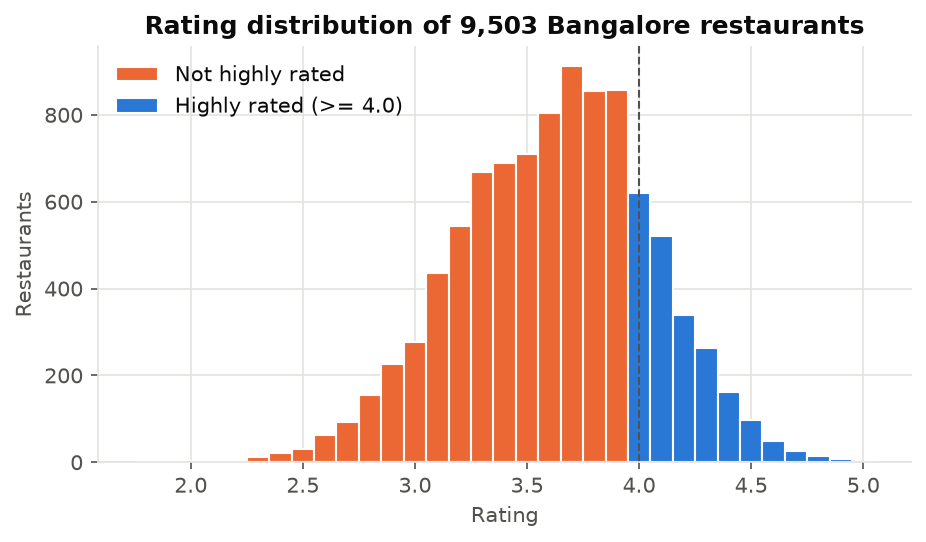

02_pivot_zone_cost.png


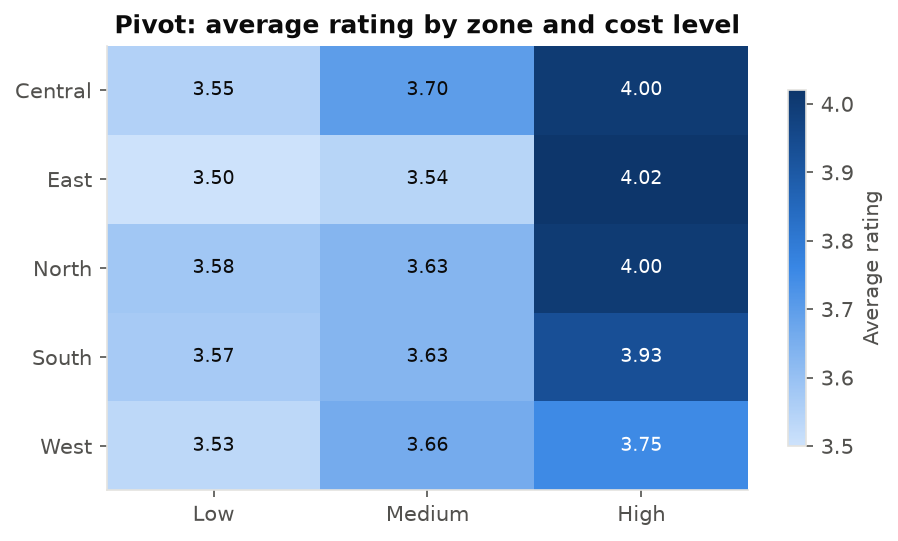

02b_zone_rollup.png


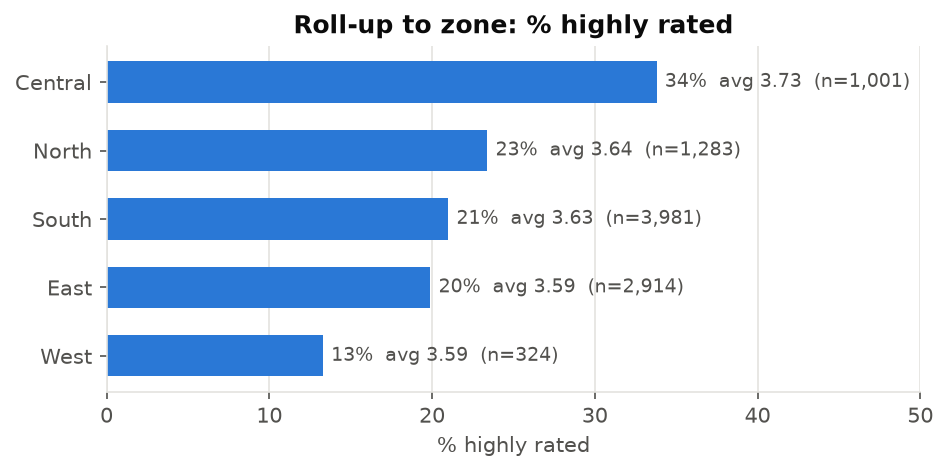

03_services_effect.png


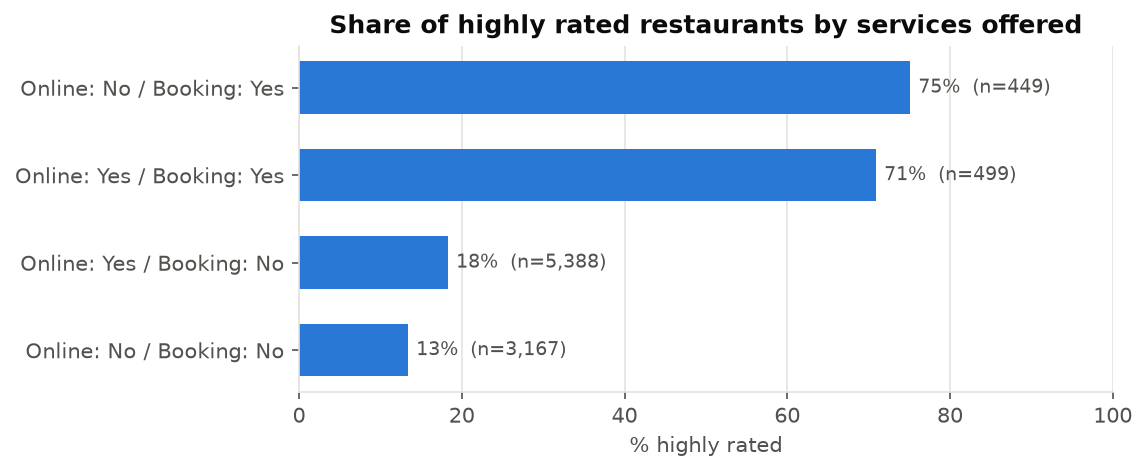

04_pattern_algorithms.png


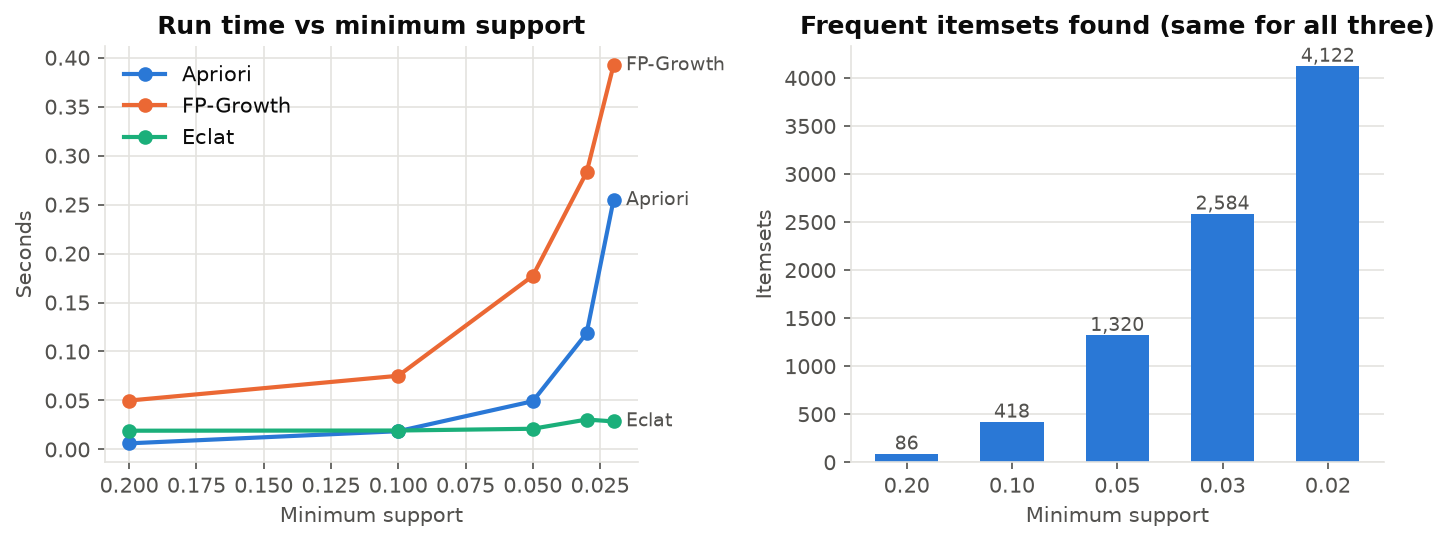

05_rules_good_rating.png


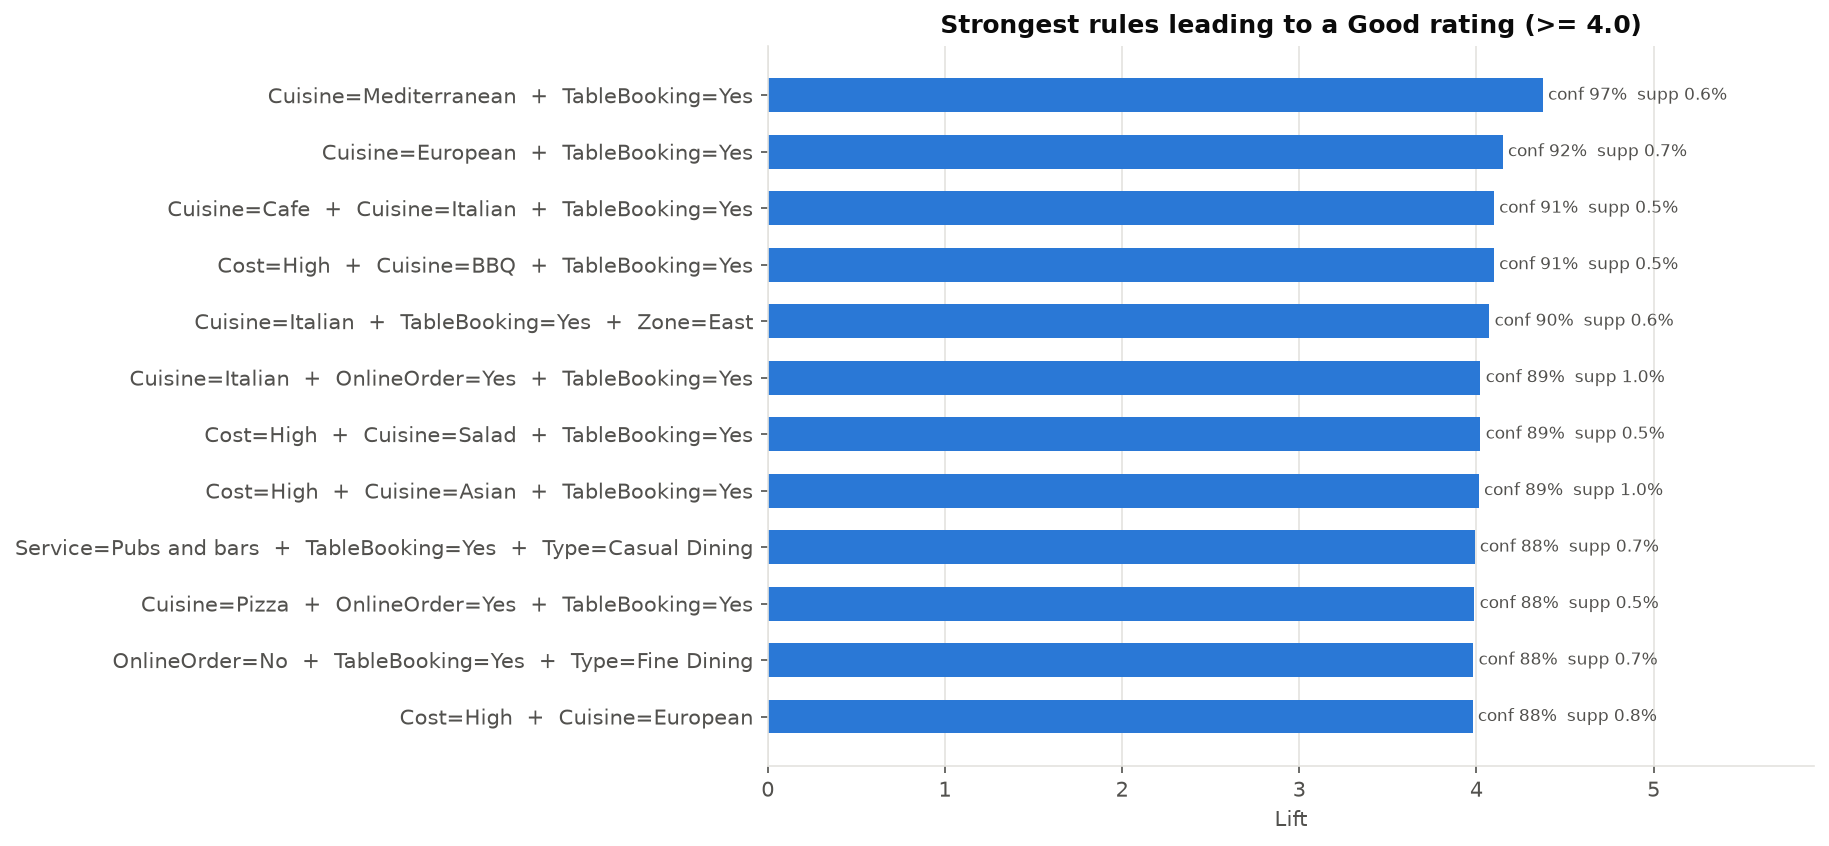

05b_rules_poor_rating.png


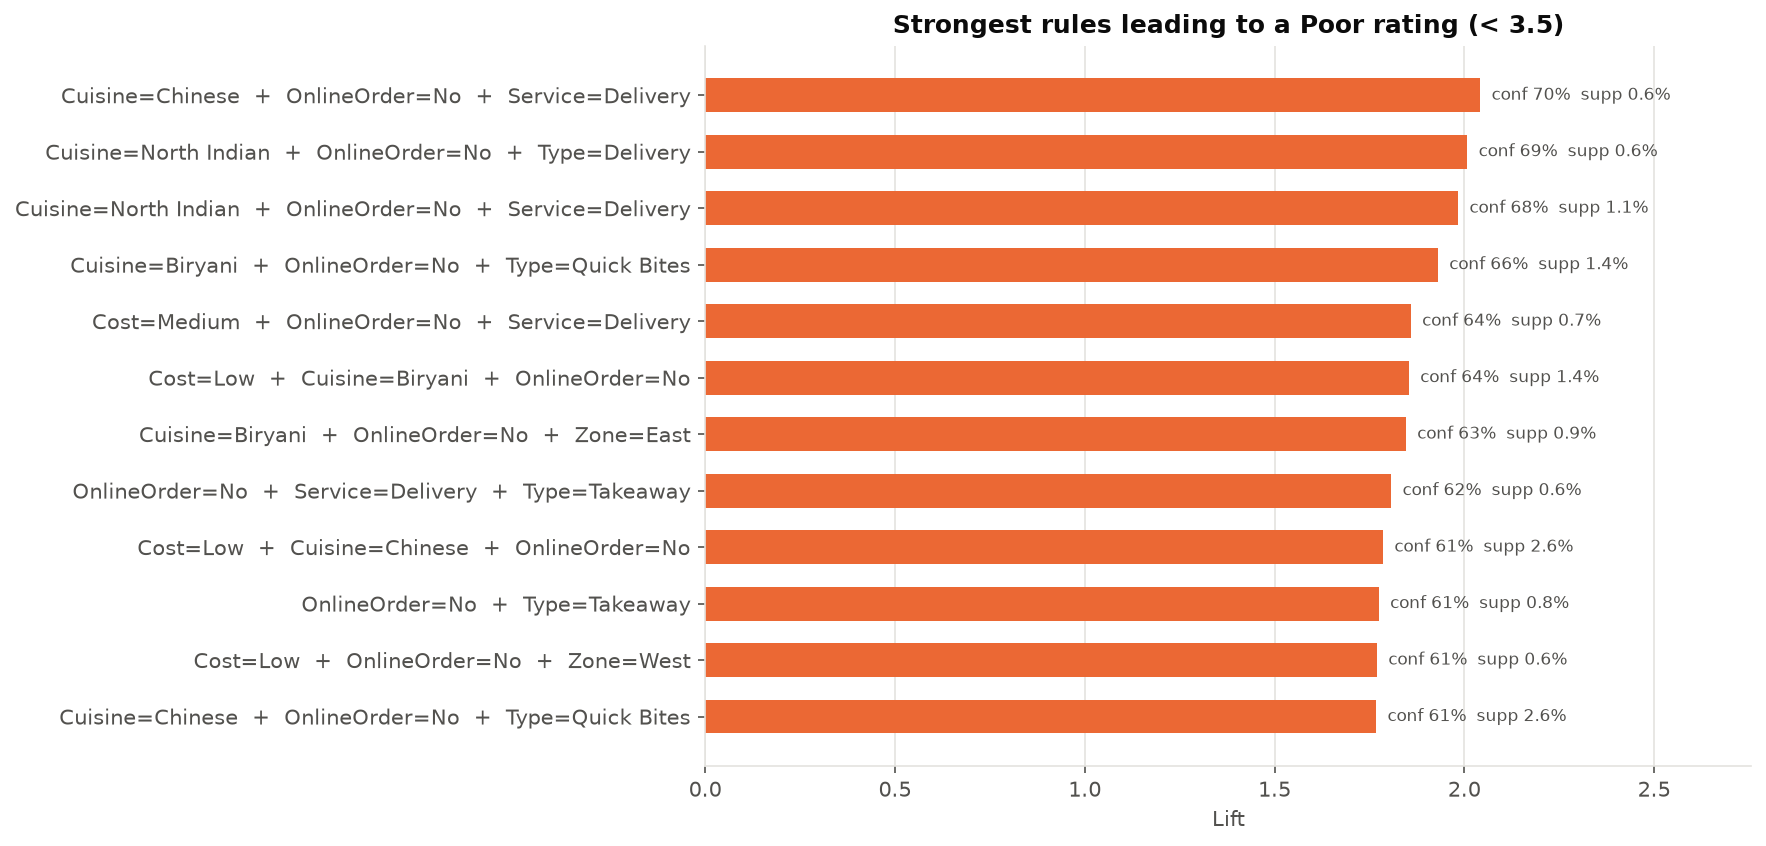

06_model_comparison.png


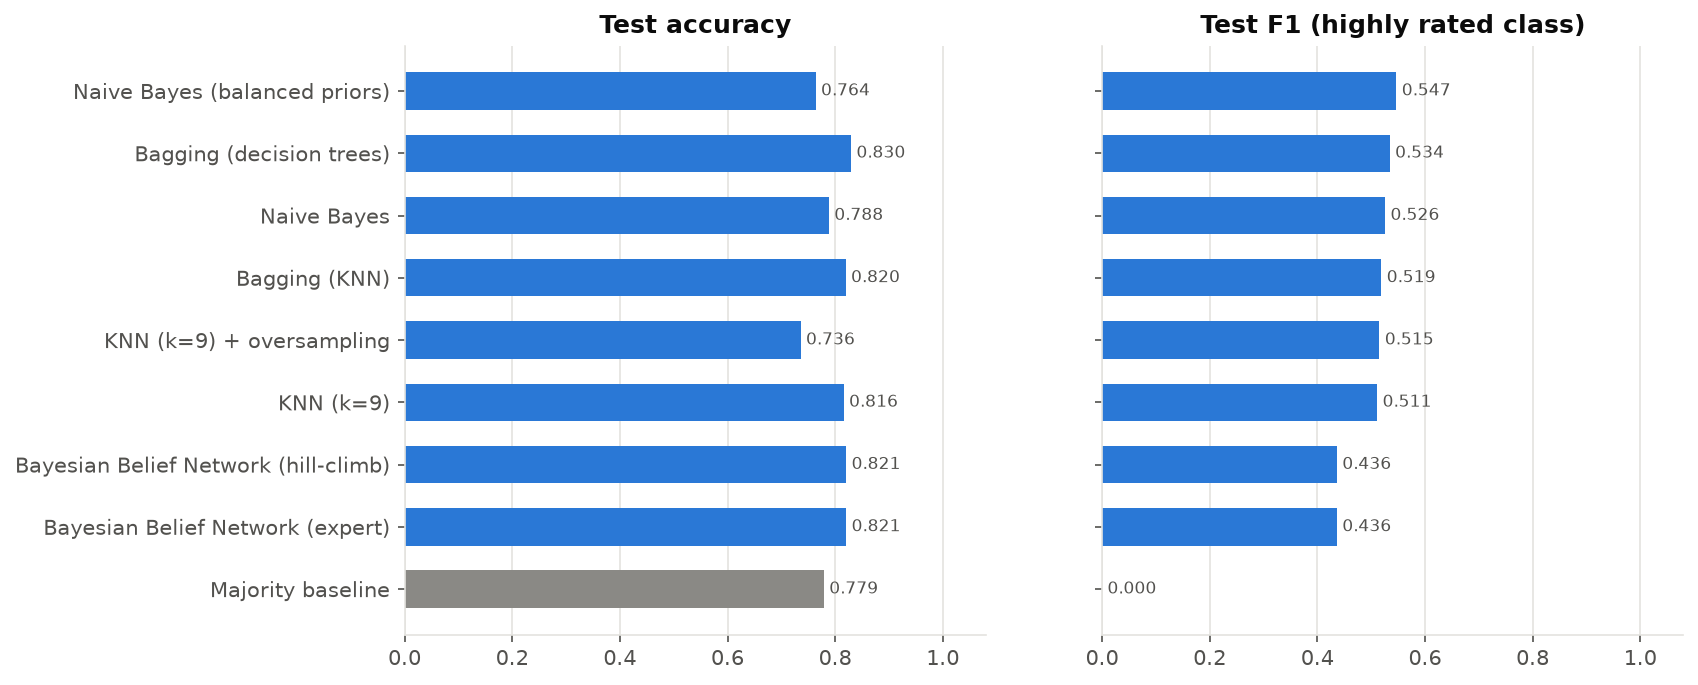

07_roc_curves.png


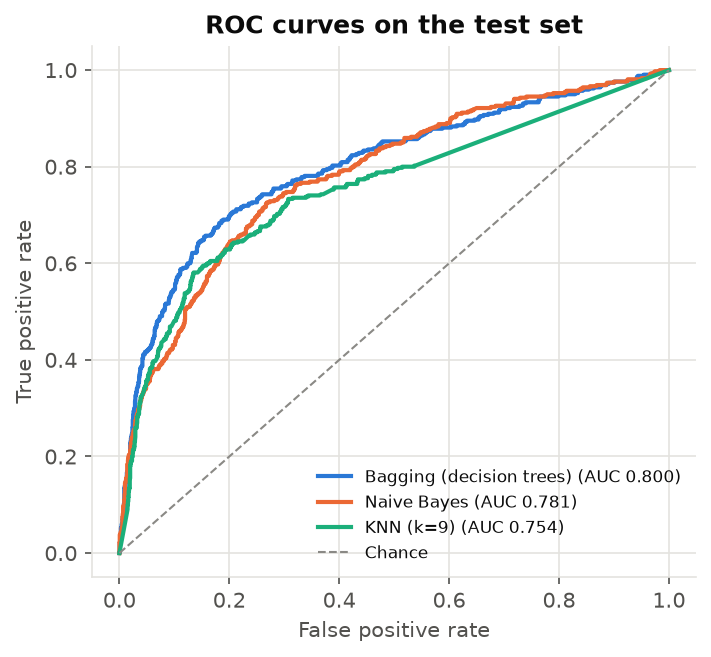

08_confusion_matrix.png


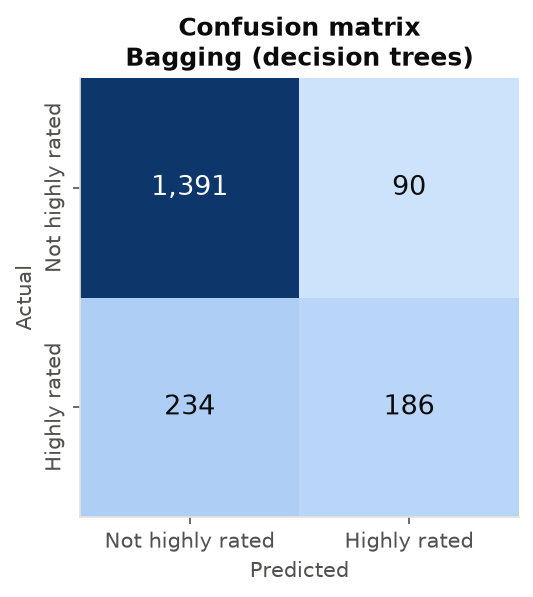

09_naive_bayes_signals.png


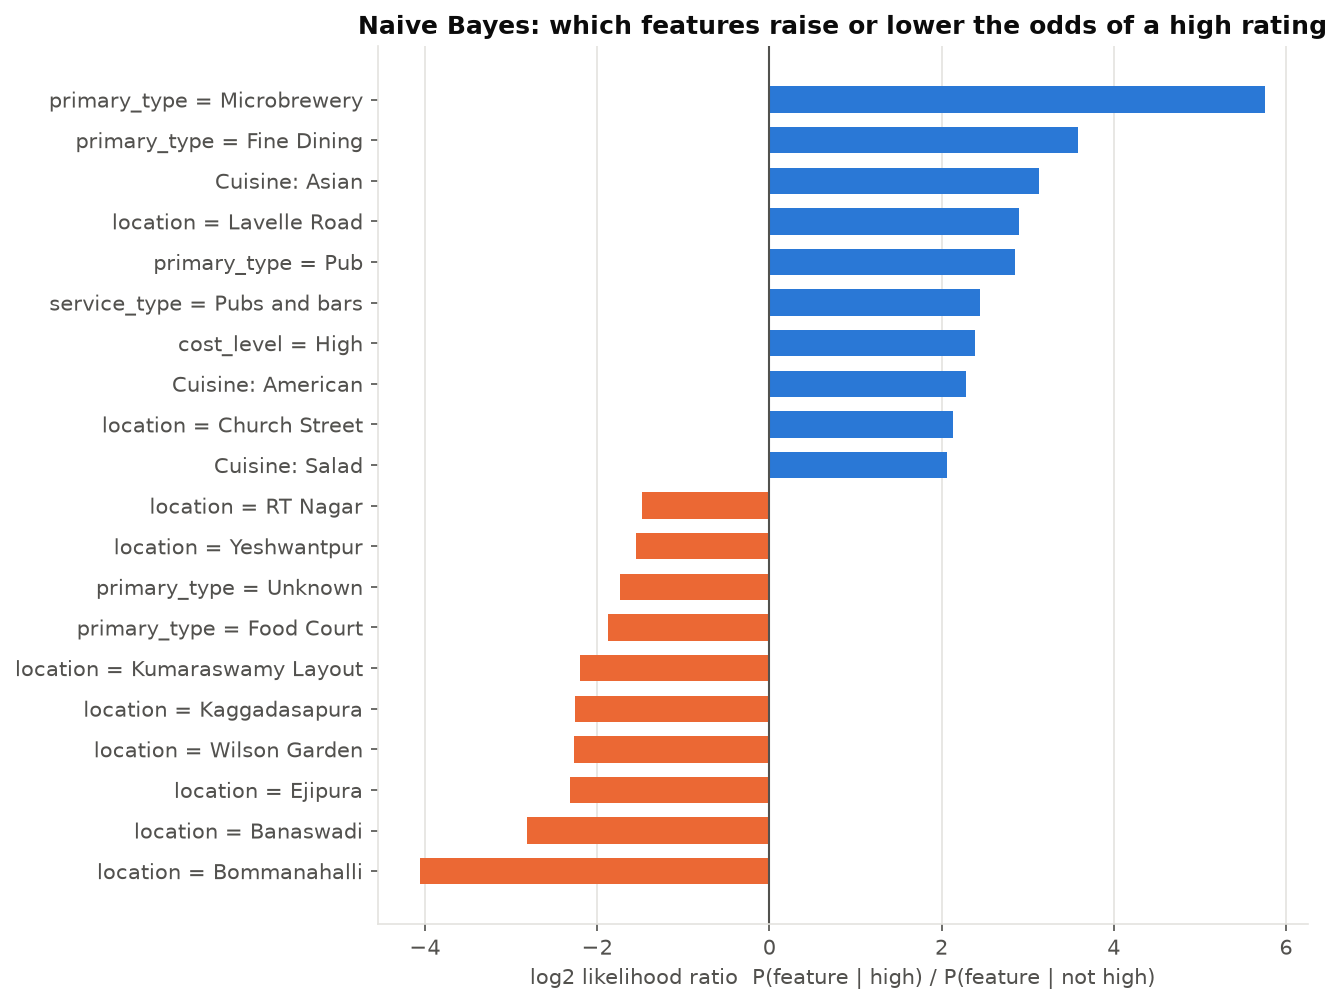

09b_bbn_expert.png


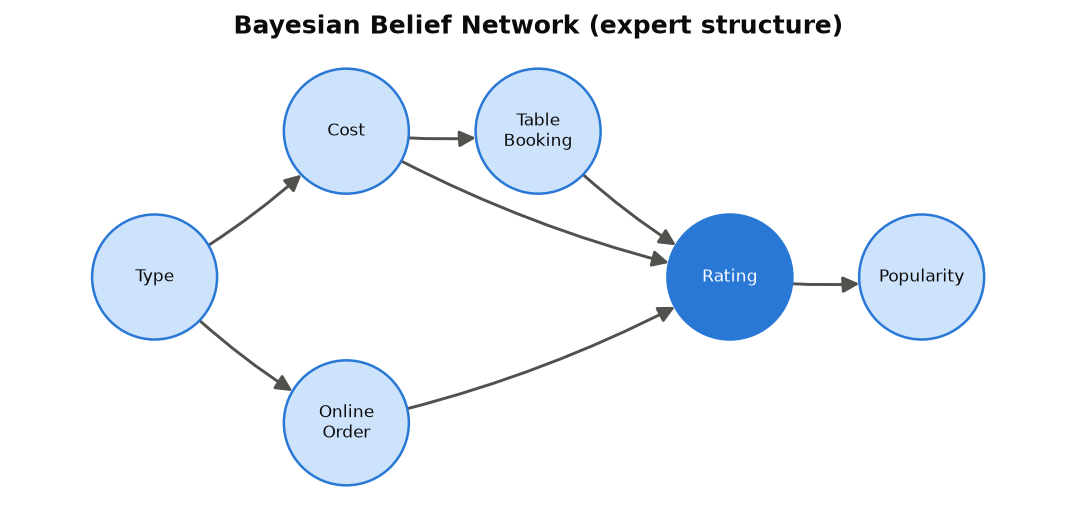

10_k_selection.png


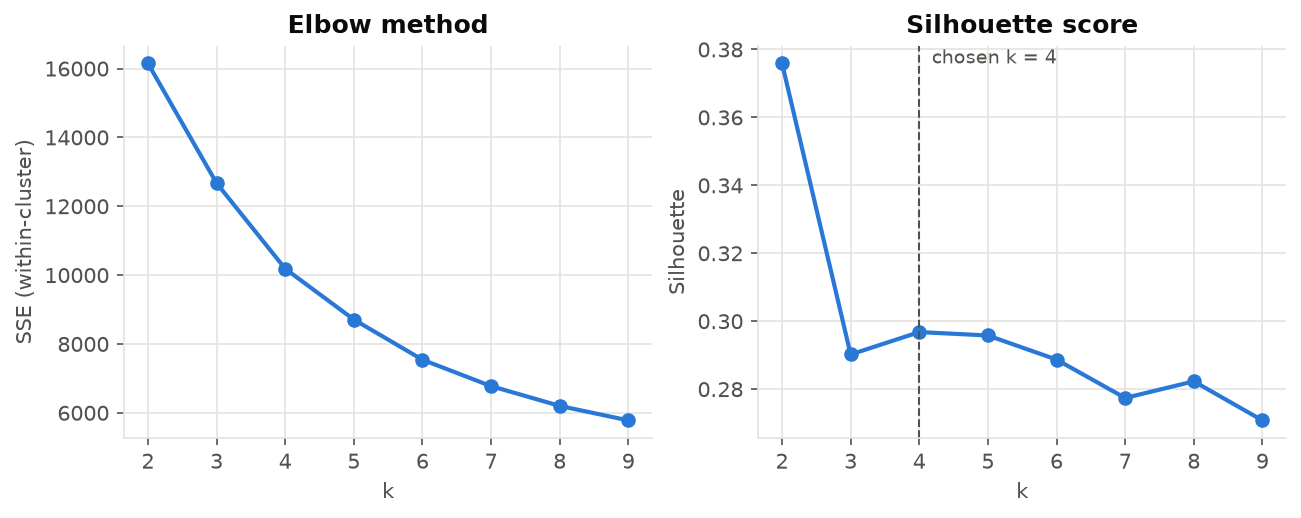

11_kmeans_clusters.png


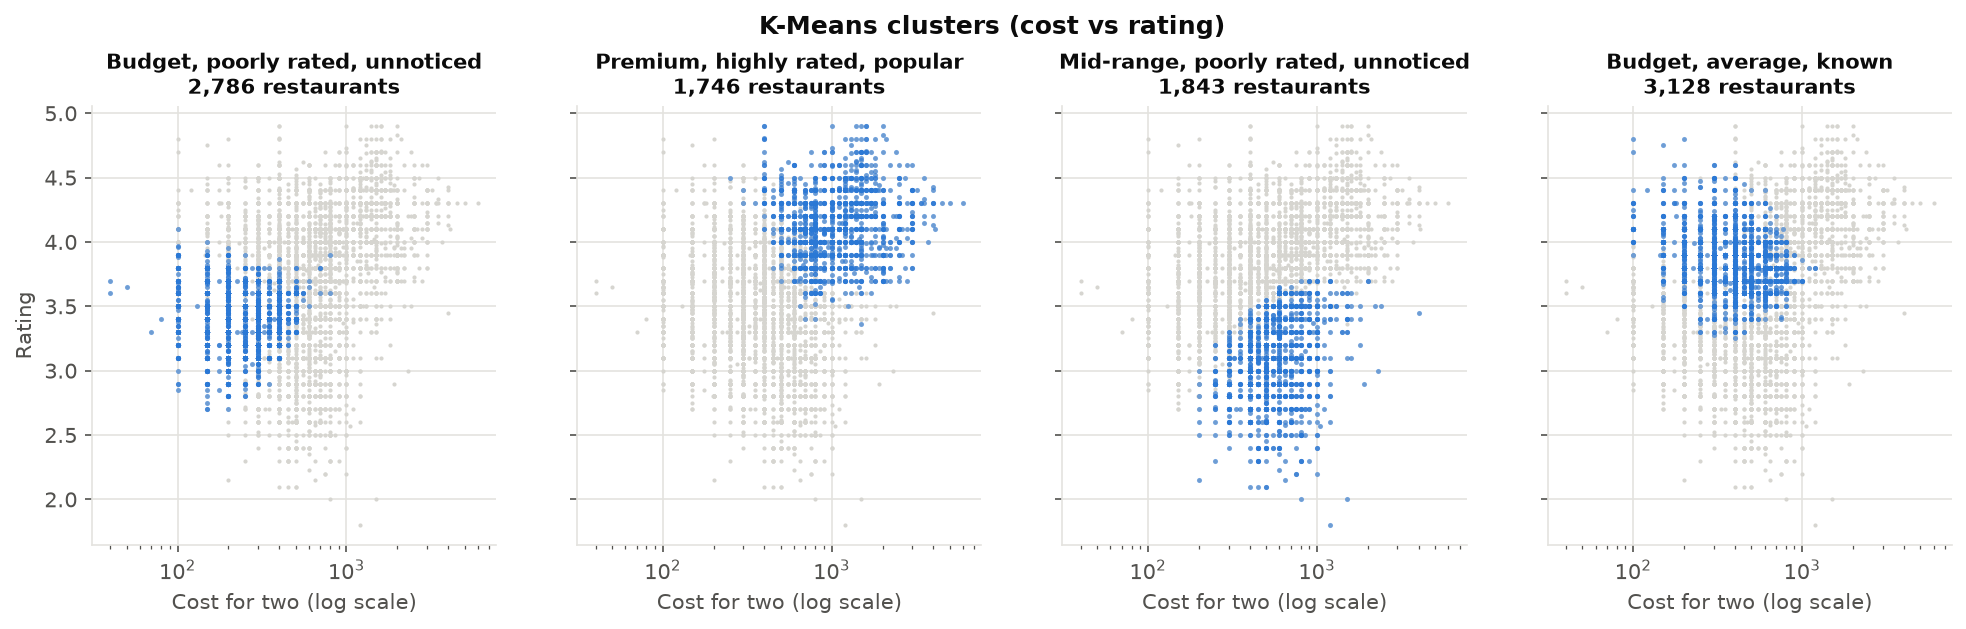

12_dbscan_outliers.png


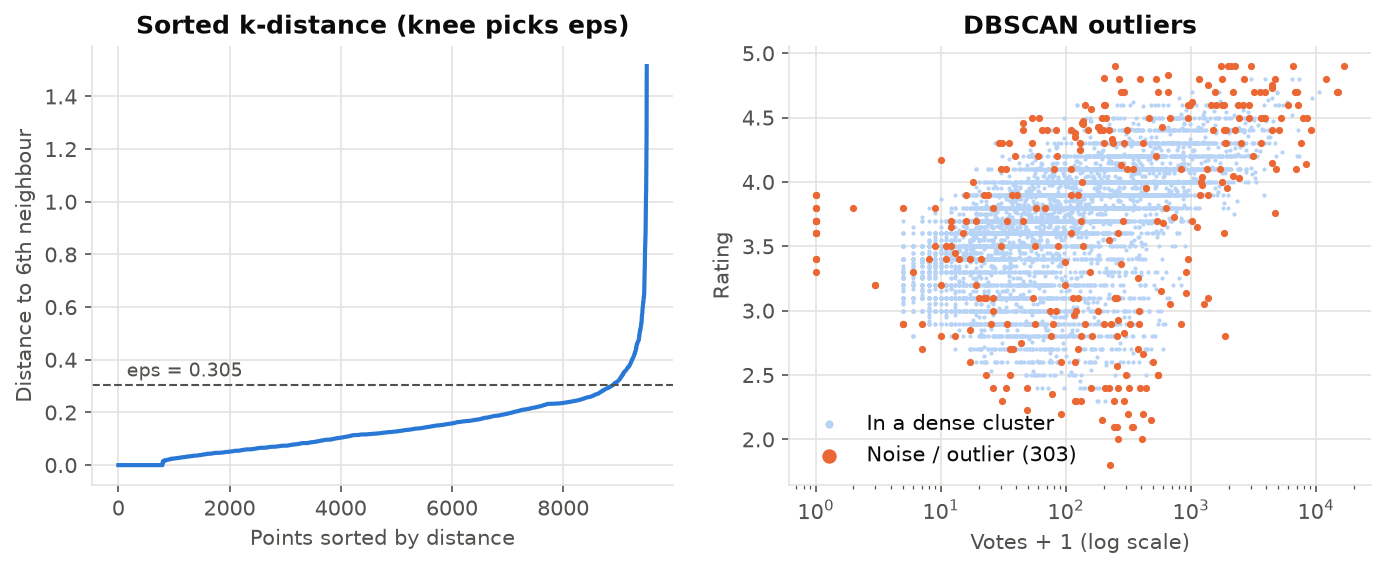

In [32]:
figures.make_all(df, olap, pats, clf, clu)
for f in sorted(config.FIG_DIR.glob('*.png')):
    print(f.name); display(Image(filename=str(f), width=820))

## Step 6: Dashboard
Run `streamlit run app.py` from the project folder.